*Note: This lab will be due after the exam, on October 14 @ midnight.*

## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<img src="./src/Intraaortic_Balloon.png" width=600>

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [3]:
df = pd.read_csv('../data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


# Answer 1:
The point estimate of ATE is (-0.01) calculated by substracting invasive survival rate (pump) from conservative (no pump) survival rate. The negative ATE says that patients who received the invasive strategy (the pump) had a 1% lower probability of survival compared to those who received the conservative, non-invasive treatment. Based on the observed survival rates alone, I would prefer not to receive the pump

**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [4]:
## Bootstrapping:
R = 10_000

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True)
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

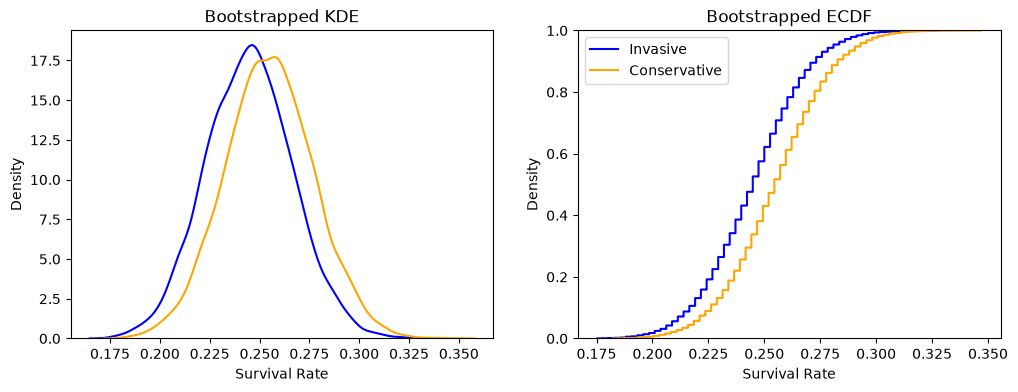

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

# Answer 3 :
Based on the bootstrapped plots, the Conservative group shows a higher survival rate than the Invasive group. In KDE plot, the distribution for the Conservative group (orange) is shifted to the right of the Invasive group (blue), showing that its average bootstrapped survival rate is higher. In bootstrapped ECDF plot, the Invasive curve (blue) sits to the left of the Conservative curve (orange) which means the Conservative group stochastically dominates, confirming higher survival probabilities overall.

**4.** Make a plot of the KDE and ECDF for the ATE. 

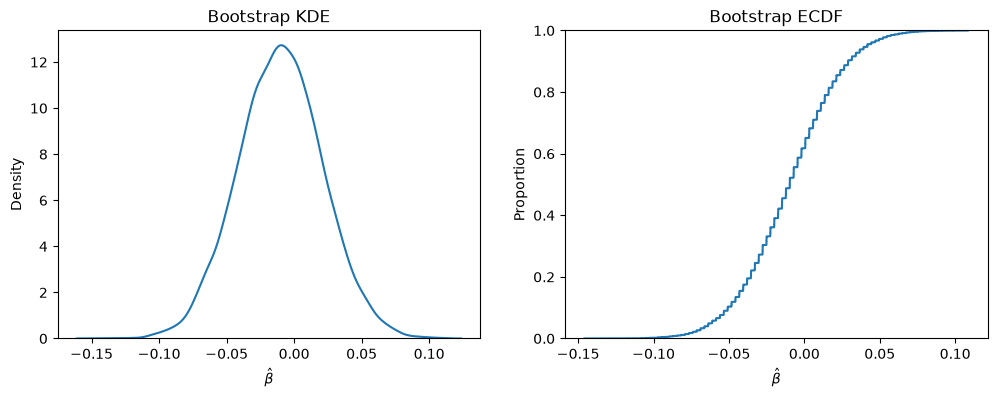

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [7]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06116662  0.04180691]
95% CI: [-0.07140964  0.05212298]
99% CI: [-0.09200839  0.07268187]


# Answer 5:

Yes, zero is included in all three confidence intervals (90%, 95%, and 99%). Because zero lies within every interval, we fail to reject the null hypothesis at all three confidence intervals. This means there is no statistically significant difference in survival rates between the Invasive and Conservative groups, and we cannot reject the hypothesis that the true treatment effect size is zero.

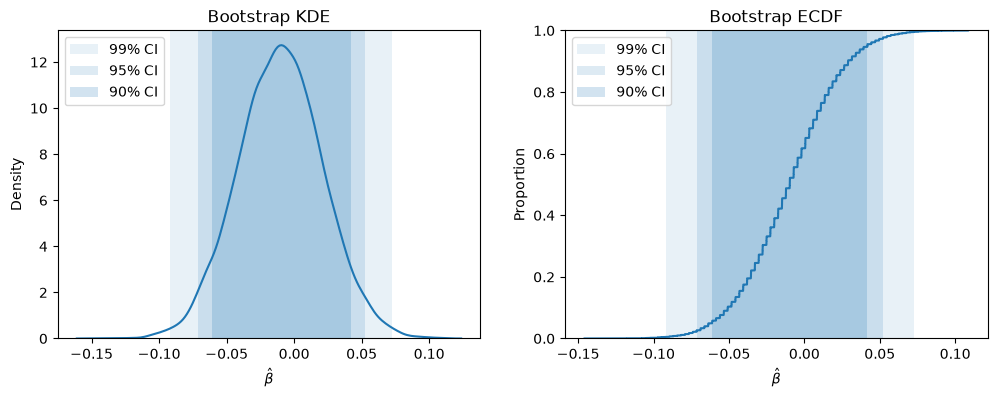

In [8]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

**6.** What have we learned about inserting balloons into hearts?

# Answer 6: 

Based on the bootstrapped KDE and ECDF plots, we have learned that inserting balloons into hearts provides no statistically significant survival benefit. The KDE plot shows the Average treatment effect distribution centered nearly at zero, and the ECDF plot is also showing that zero falls right near the middle of the cumulative probability. Also, Because all three confidence intervals contain zero, the treatment effect of inserting intra-aortic balloon pumps into the heart remains statistically insignificant compared to non-invasive method. 

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

# Part 2.1

In [41]:
df2 = pd.read_csv("../data/diabetes.csv")
df2["y"] = (df2["outcome"] == "success").astype(int)   # 1 = success, 0 = failure

print(pd.crosstab(df2["treatment"], df2["outcome"], margins=True), "\n")
print(pd.crosstab(df2["treatment"], df2["outcome"], normalize="index").round(3), "\n")
print(df2.groupby("treatment")["y"].mean().round(3))


outcome    failure  success  All
treatment                       
lifestyle      109      125  234
met            120      112  232
rosi            90      143  233
All            319      380  699 

outcome    failure  success
treatment                  
lifestyle    0.466    0.534
met          0.517    0.483
rosi         0.386    0.614 

treatment
lifestyle    0.534
met          0.483
rosi         0.614
Name: y, dtype: float64


# Part 2.2

In [43]:
np.random.seed(42)          # reproducible results
R = 10_000
arms = ["met", "rosi", "lifestyle"]
boot = {arm: [] for arm in arms}

for arm in arms:
    y_arm = df2.loc[df2["treatment"] == arm, "y"]       # only this arm's outcomes
    for _ in range(R):
        boot[arm].append(y_arm.sample(frac=1.0, replace=True).mean())

boot = pd.DataFrame(boot)   # 10,000 rows x 3 columns, one bootstrapped success rate per arm
print(boot.describe().round(3))

             met       rosi  lifestyle
count  10000.000  10000.000  10000.000
mean       0.483      0.614      0.534
std        0.033      0.032      0.032
min        0.362      0.476      0.423
25%        0.461      0.592      0.513
50%        0.483      0.614      0.534
75%        0.504      0.635      0.556
max        0.608      0.730      0.671


# Part 2.3

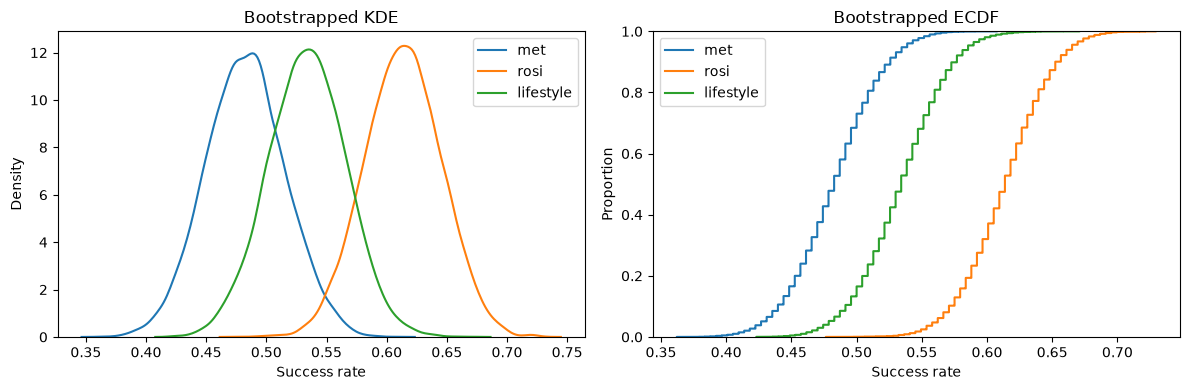

In [44]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for arm in arms:
    sns.kdeplot(boot[arm], label=arm, ax=ax[0])
    sns.ecdfplot(boot[arm], label=arm, ax=ax[1])
ax[0].set(title="Bootstrapped KDE", xlabel="Success rate", ylabel="Density")
ax[1].set(title="Bootstrapped ECDF", xlabel="Success rate", ylabel="Proportion")
ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.show()

Both the Kernel Density Estimate (KDE) and the Empirical Cumulative Distribution Function (ECDF) indicate that rosiglitazone achieved the highest success rate, with its distribution centered around 62%. The lifestyle intervention occupies the middle tier with a success rate centered near 54%, while metformin performs the poorest, peaking around 49%.

# Part 2.4

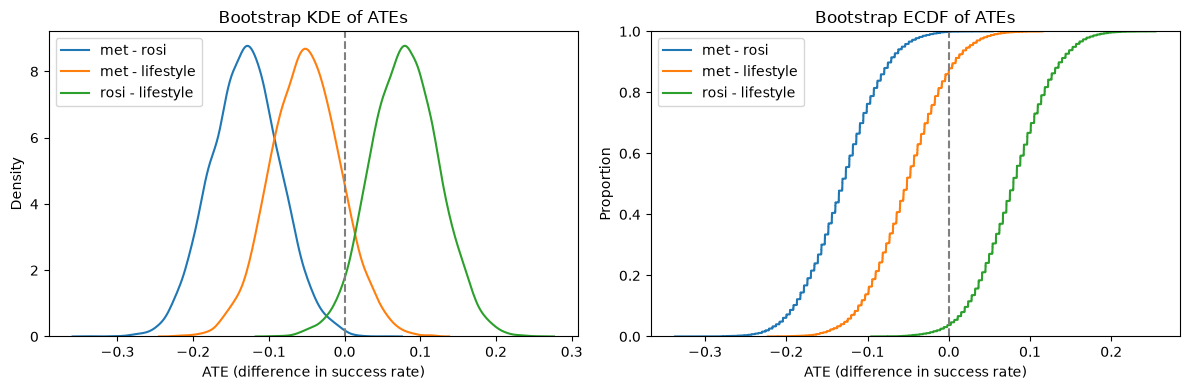

In [45]:
ate = pd.DataFrame({
    "met - rosi":       boot["met"] - boot["rosi"],
    "met - lifestyle":  boot["met"] - boot["lifestyle"],
    "rosi - lifestyle": boot["rosi"] - boot["lifestyle"],
})

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for c in ate.columns:
    sns.kdeplot(ate[c], label=c, ax=ax[0])
    sns.ecdfplot(ate[c], label=c, ax=ax[1])
for a in ax:
    a.axvline(0, color="gray", ls="--")
ax[0].set(title="Bootstrap KDE of ATEs", xlabel="ATE (difference in success rate)")
ax[1].set(title="Bootstrap ECDF of ATEs", xlabel="ATE (difference in success rate)")
ax[0].legend(); ax[1].legend()
plt.tight_layout()
plt.show()

# Part 2.5

In [46]:
rows = []
for c in ate.columns:
    lo90, hi90 = np.quantile(ate[c], [.05, .95])
    lo95, hi95 = np.quantile(ate[c], [.025, .975])
    lo99, hi99 = np.quantile(ate[c], [.005, .995])
    rows.append({"comparison": c, "ATE": ate[c].mean(),
                 "90% CI": f"[{lo90:.3f}, {hi90:.3f}]", "0 in 90%?": lo90 <= 0 <= hi90,
                 "95% CI": f"[{lo95:.3f}, {hi95:.3f}]", "0 in 95%?": lo95 <= 0 <= hi95,
                 "99% CI": f"[{lo99:.3f}, {hi99:.3f}]", "0 in 99%?": lo99 <= 0 <= hi99})
ci_table = pd.DataFrame(rows).round(3)
print(ci_table.to_string(index=False))

      comparison    ATE           90% CI  0 in 90%?           95% CI  0 in 95%?           99% CI  0 in 99%?
      met - rosi -0.131 [-0.204, -0.054]      False [-0.221, -0.041]      False [-0.247, -0.011]      False
 met - lifestyle -0.051  [-0.125, 0.026]       True  [-0.142, 0.039]       True  [-0.167, 0.069]       True
rosi - lifestyle  0.080   [0.007, 0.157]      False  [-0.010, 0.169]       True  [-0.041, 0.195]       True


# Confidence Interval

• met – rosi: This is the only comparison that remains statistically significant across all levels (90%, 95%, and 99%). Because the intervals strictly contain negative values (e.g., [-0.247, -0.011] at 99%) and do not include zero, we can confidently conclude that rosi performs significantly better than met.

• met – lifestyle: This difference is not statistically significant at any level. The confidence intervals include zero across the board (e.g., [-0.125, 0.026] at 90%), meaning we cannot conclusively state that a true difference exists between met and lifestyle.

• rosi – lifestyle: This comparison is statistically significant only at the 90% confidence level ([0.007, 0.157], where 0 is excluded). However, as the confidence requirement tightens to 95% and 99%, the intervals widen to include zero ([-0.010, 0.169] and [-0.041, 0.195]), rendering the result not statistically significant at higher thresholds.